# สร้าง Model คัดแยก SMS

### นิยามความหมายของ `group` และ `sub_group`

**`group` (กลุ่มหลัก — 2 คลาส):**
- **`positive`** (861 แถว): ข้อความ SMS ปกติ / ข้อความจากระบบหรือองค์กรที่มีตัวตนจริง
- **`negative`** (462 แถว): ข้อความ SMS หลอกลวง / สแปม / มิจฉาชีพ

**`sub_group` (กลุ่มย่อย — 8 คลาส):**

| `group` | `sub_group` | จำนวน | ความหมาย |
| :--- | :--- | ---: | :--- |
| `positive` | `promotion` | 532 | SMS โปรโมชันสินค้า สิทธิพิเศษ พอยท์ และบริการทางการค้า |
| `positive` | `carrier_vas` | 151 | SMS บริการเสริมจากค่ายมือถือ (เช่น ดูดวง ริงโทน กด `*...#`) |
| `positive` | `otp` | 70 | SMS รหัส OTP / รหัสยืนยันตัวตนในการทำรายการ |
| `positive` | `service_notice` | 63 | SMS แจ้งเตือนบริการ สถานะพัสดุ ระบบโทรศัพท์ และประกาศภาครัฐ |
| `positive` | `payment_alert` | 45 | SMS แจ้งชำระเงิน ยอดค้างชำระ เงินเข้า-ออก และธุรกรรมทางการเงิน |
| `negative` | `invite` | 293 | SMS ชักชวนเว็บพนัน แจกเครดิตฟรี รางวัลปลอม กู้เงินเถื่อน และงานออนไลน์ |
| `negative` | `phishing_link` | 129 | SMS แนบลิงก์ฟิชชิ่ง ปลอมเป็นธนาคาร ขนส่ง หรือหน่วยงานรัฐเพื่อขโมยข้อมูล |
| `negative` | `threat` | 40 | SMS ข่มขู่ / แจ้งเตือนเท็จ (เช่น พัสดุถูกอายัด ตัดไฟ หมายเรียก) เพื่อกดดันให้รีบดำเนินการ |

### install & import libarry

In [20]:
# !pip install pandas pythainlp scikit-learn matplotlib

import re, math, time, unicodedata, itertools, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from functools import lru_cache
from scipy.sparse import hstack, csr_matrix
from pythainlp.tokenize import word_tokenize
from pythainlp.util import normalize as th_normalize
from pythainlp.corpus import thai_words, thai_stopwords
from pythainlp.corpus.tnc import word_freqs
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)


### รวม Function Visualization
จุดที่ต้องการใส่ Visualization ให้ประการ cell code ไว้ล่างเซลนี้ โดย 1 Function ต่อ 1 cell

In [21]:
def plot_hierarchical_results(y_true_grp, y_pred_grp, y_true_sub, y_pred_sub):
    grp_acc = accuracy_score(y_true_grp, y_pred_grp)
    grp_f1  = f1_score(y_true_grp, y_pred_grp, average="macro")
    sub_acc = accuracy_score(y_true_sub, y_pred_sub)
    sub_f1  = f1_score(y_true_sub, y_pred_sub, average="macro")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.8]})

    # Confusion Matrix: group
    grp_labels = ["positive", "negative"]
    cm_grp = confusion_matrix(y_true_grp, y_pred_grp, labels=grp_labels)
    ConfusionMatrixDisplay(cm_grp, display_labels=grp_labels).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"Stage 1: group (LinearSVC)\nAcc: {grp_acc:.2%} | F1-macro: {grp_f1:.2%}", fontsize=11)

    # Confusion Matrix: sub_group
    sub_labels = sorted(y_true_sub.unique())
    cm_sub = confusion_matrix(y_true_sub, y_pred_sub, labels=sub_labels)
    ConfusionMatrixDisplay(cm_sub, display_labels=sub_labels).plot(
        ax=axes[1], cmap="Greens", colorbar=False, xticks_rotation=35
    )
    axes[1].set_title(f"Stage 2: sub_group (LogisticRegression)\nAcc: {sub_acc:.2%} | F1-macro: {sub_f1:.2%}", fontsize=11)

    plt.tight_layout()
    plt.show()


In [22]:
def plot_cv_stability(cv_df, metrics=("group_f1", "scam_recall", "sub_f1", "sub_pos_f1", "sub_neg_f1"), title="Cross-validation stability"):
    """Boxplot ของคะแนนแต่ละรอบ (fold) เพื่อดูว่าค่าความแม่นยำนิ่งแค่ไหน"""
    metrics = [m for m in metrics if m in cv_df.columns]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.boxplot([cv_df[m] for m in metrics], showmeans=True, widths=0.5)
    rng = np.random.default_rng(0)
    for i, m in enumerate(metrics, start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(cv_df)), cv_df[m], s=14, alpha=0.5)
        ax.text(i, ax.get_ylim()[0], f"{cv_df[m].mean():.3f} ± {cv_df[m].std():.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(1, len(metrics) + 1), metrics)
    ax.set_ylabel("score")
    ax.set_title(f"{title} ({len(cv_df)} folds)", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


### ดึง Data ที่เตรียมไว้จาก data_set.csv

In [23]:
df = pd.read_csv("data_set.csv", encoding="utf-8-sig")

print(f"จำนวนข้อมูลทั้งหมด: {len(df)} แถว")
print("\nสัดส่วน group:")
print(df["group"].value_counts())
display(df.head())

จำนวนข้อมูลทั้งหมด: 1323 แถว

สัดส่วน group:
group
positive    861
negative    462
Name: count, dtype: int64


,id,sentence_raw,group,sub_group,source
0,1,เปิดดวงรับโชค ลุ้น 300 บาท กด *451# สมัครดวงรา...,positive,carrier_vas,tonkla_phone
1,2,ขอบคุณที่ชำระ 535 บ. 01/03/2024 <URL>,positive,payment_alert,Zoleir/Fraud-SMS-Detection-Application
2,3,Lazada เซลใหญ่วันเกิด แบรนด์ดังลดแรง สูงสุด 90...,positive,promotion,Zoleir/Fraud-SMS-Detection-Application
3,4,เมษานี้เย็นใจกับแป้นพิมพ์มือถือ Emerald Thai W...,positive,carrier_vas,ter_phone
4,5,1-20 เม.ย.68 ร่วมตอบแบบสอบถามสำมะโนประชากรและเ...,positive,service_notice,ter_phone


## NLP

### Normalize data ไม่สำคัญให้อยู่ในรูป <TAG>

In [24]:
# รูปแบบของ <TAG>
URL_RE = re.compile(
    r"(?:https?://[^\s<>\"']+|(?:www\.|lin\.ee/|cutt\.ly/|bit\.ly/|shorturl\.at/|urlzs\.com/|m\.ais\.co\.th/|s\.true\.th/)[A-Za-z0-9._~:/?#\[\]@!$&'()*+,;=%-]+|\b[A-Za-z0-9-]+\.(?:com|net|org|me|vip|fun|xyz|club|cc|info|top|site|online|shop|bet|win|live|asia|co\.th)(?:/[^\s<>\"']*)?)",
    re.IGNORECASE,
)
LINE_RE = re.compile(r"(?:(?:ไลน์|line|id|ไอดี)\s*[:：]?\s*)?@[A-Za-z0-9._-]{3,}", re.IGNORECASE)
USSD_RE = re.compile(r"\*\d+(?:\*\d+)*#|\b\d{4,6}#")
DATE_RE = re.compile(
    r"\b\d{1,2}/\d{1,2}/\d{2,4}\b|\d{1,2}\s*(?:ม\.ค\.|ก\.พ\.|มี\.ค\.|เม\.ย\.|พ\.ค\.|มิ\.ย\.|ก\.ค\.|ส\.ค\.|ก\.ย\.|ต\.ค\.|พ\.ย\.|ธ\.ค\.)\s*\d{2,4}"
)
TIME_RE = re.compile(r"\b\d{1,2}[:.]\d{2}\s*น\.")
OTP_RE = re.compile(
    r"<OTP\s+\d{4,8}>|\bOTP\s*(?:is|=|:)?\s*\d{4,8}\b|\b\d{6}(?=\s+is your\b)",
    re.IGNORECASE,
)
OTP_TH_RE = re.compile(r"(รหัส(?:ยืนยัน|ผ่านครั้งเดียว|รักษาความปลอดภัย)[^\d\n]{0,15})\b\d{4,8}\b")
REF_RE = re.compile(
    r"<Ref\.[A-Za-z0-9]+>|\bRef(?:erence)?(?:\s*code)?\s*[:.=]?\s*[A-Za-z0-9]{3,8}\b",
    re.IGNORECASE,
)
REF_TH_RE = re.compile(r"(รหัสอ้างอิง[^\dA-Za-z\n]{0,10})[A-Za-z0-9]{4,8}")
PHONE_RE = re.compile(r"\b0\d{1,2}[-\s]?\d{3,4}[-\s]?\d{3,4}\b|\b0\d{2}-[xX]{3}-\d{4}\b")
AMOUNT_RE = re.compile(r"\d[\d,]*(?:\.\d+)?\s*(?:บาท|บ\.|บ(?=\s|/|$|\))|\.-)")


In [25]:
def normalize_sms(text: str) -> str:
    s = re.sub(r"\s+", " ", str(text).replace("\xa0", " ")).strip()
    s = URL_RE.sub("<URL>", s)
    s = LINE_RE.sub("<LINE_ID>", s)
    s = USSD_RE.sub("<USSD>", s)
    s = DATE_RE.sub("<DATE>", s)
    s = TIME_RE.sub("<TIME>", s)
    s = OTP_RE.sub("<OTP>", s)
    s = OTP_TH_RE.sub(r"\1<OTP>", s)
    s = REF_RE.sub("<REF>", s)
    s = REF_TH_RE.sub(r"\1<REF>", s)
    s = PHONE_RE.sub("<PHONE>", s)
    s = AMOUNT_RE.sub(" <AMOUNT> ", s)
    s = re.sub(r"\s*(<[A-Z_]+>)\s*", r" \1 ", s)
    return re.sub(r"\s+", " ", s).strip()

df["sentence"] = df["sentence_raw"].apply(normalize_sms)

# แสดงตัวอย่างเปรียบเทียบก่อนและหลังแปลง <TAG>
sample_df = df[["sentence_raw", "sentence", "group", "sub_group"]].sample(10, random_state=42)
for i, row in sample_df.iterrows():
    print(f"[{row['group']} | {row['sub_group']}]")
    print(f"  RAW : {row['sentence_raw']}")
    print(f"  TAG : {row['sentence']}\n")

display(sample_df)

[negative | invite]
  RAW : ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>
  TAG : ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>

[positive | promotion]
  RAW : ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada <URL>
  TAG : ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada <URL>

[positive | otp]
  RAW : กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รหัส OTP ของคุณคือ <OTP> (อ้างอิง: <REF>) ใช้ได้ 10 นาที หมดอายุ 2026-11-06 07:18
  TAG : กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รหัส OTP ของคุณคือ <OTP> (อ้างอิง: <REF> ) ใช้ได้ 10 นาที หมดอายุ 2026-11-06 07:18

[positive | otp]
  RAW : OTP <OTP> (ref.<REF>) สำหรับเข้าสู่ระบบ myAIS กรุณาอย่าบอกรหัสผู้อื่น
  TAG : OTP <OTP> (ref. <REF> ) สำหรับเข้าสู่ระบบ myAIS กรุณาอย่าบอกรหัสผู้อื่น

[negative | invite]
  RAW : สมัครใหม่ รับฟรี 50บาท ถoนไม่อั้น!คลิก  https://urlzs.com/o8Yz7
  TAG : สมัครใหม่ รับฟรี <AMOUNT> ถoนไม่อั้น!คลิก <URL>

[positive | otp]
  RAW : รหัส OTP ของคุณคือ [OTP] รหัสสามารถใช้ได้ถึง 10:17:27 น.
  TAG : รหัส OTP ของคุณคือ [OTP] รหัสสามา

,sentence_raw,sentence,group,sub_group
727,ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>,ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>,negative,invite
479,ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada ...,ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada ...,positive,promotion
240,กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รห...,กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รห...,positive,otp
422,OTP <OTP> (ref.<REF>) สำหรับเข้าสู่ระบบ myAIS ...,OTP <OTP> (ref. <REF> ) สำหรับเข้าสู่ระบบ myAI...,positive,otp
49,สมัครใหม่ รับฟรี 50บาท ถoนไม่อั้น!คลิก https:...,สมัครใหม่ รับฟรี <AMOUNT> ถoนไม่อั้น!คลิก <URL>,negative,invite
291,รหัส OTP ของคุณคือ [OTP] รหัสสามารถใช้ได้ถึง 1...,รหัส OTP ของคุณคือ [OTP] รหัสสามารถใช้ได้ถึง 1...,positive,otp
873,Flash Sale ดีลเด็ด! เน็ตเต็มสปีด 99GB 7วัน แค่...,Flash Sale ดีลเด็ด! เน็ตเต็มสปีด 99GB 7วัน แค่...,positive,promotion
994,รหัสยืนขัน <OTP> ใช้ใต้ภายใน 10 นาที อย่าเปิดเ...,รหัสยืนขัน <OTP> ใช้ใต้ภายใน 10 นาที อย่าเปิดเ...,positive,otp
567,ลุ้นทริปสายมู รับโชคทองแสน กับ อ.คฑา กด *471*8...,ลุ้นทริปสายมู รับโชคทองแสน กับ อ.คฑา กด <USSD>...,positive,carrier_vas
549,มีนา ดวงเด่น! ลุ้นรับโชคใหญ่รถยนต์ Suzuki SWIF...,มีนา ดวงเด่น! ลุ้นรับโชคใหญ่รถยนต์ Suzuki SWIF...,positive,carrier_vas


### Tokenization แบ่งคำโดยรักษาความหมายของประโยค
- ตัดคำภาษาไทยจาก `df["sentence"]` (เช่น ใช้ `pythainlp.word_tokenize` ด้วย engine `newmm` หรือ `attacut`)
- **ข้อควรระวัง:** ตั้งค่าหรือจัดการไม่ให้ `<TAG>` (เช่น `<URL>`, `<AMOUNT>`, `<OTP>`) ถูกตัดแยกเป็นคำย่อย และลองทดลองว่าจะตัด Stopwords หรือคงไว้

In [26]:
LOOKALIKES = {
    "II": ["แ"], "ll": ["แ"], "Il": ["แ"], "lI": ["แ"],
    "I":  ["เ"], "l":  ["เ"], "|":  ["เ"],
    "o":  ["อ"], "O":  ["อ"], "0":  ["อ"],
    "u":  ["น", "บ"], "U": ["บ", "น"],
    "n":  ["ก", "ท"],
    "s":  ["ร", "ธ"], "S": ["ร", "ธ"],
    "w":  ["พ", "ฟ", "ฬ"], "W": ["ฟ", "พ", "ฬ"],
}

_UNIT        = re.compile("|".join(map(re.escape, sorted(LOOKALIKES, key=len, reverse=True))))
_CHUNK       = re.compile(rf"(?<![A-Za-z0-9])(?:[ก-๙]*(?:{_UNIT.pattern}))+[ก-๙]+(?![A-Za-z0-9])")
_ZERO_WIDTH  = re.compile(r"[\u200b-\u200d\u2060\ufeff]")
_PAREN       = re.compile(r"([\(\)])")
_FREQ        = dict(word_freqs())
_LOG_TOTAL   = math.log(sum(_FREQ.values()))
_DICT        = set(thai_words())
STOPWORDS    = thai_stopwords()
_NEGATIONS = {"ไม่", "ไม่ได้", "ไม่มี", "ไม่ใช่", "ห้าม", "อย่า", "มิ", "มิได้", "มิใช่", "ไม่ค่อย"}


@lru_cache(maxsize=200_000)
def _word_cost(word: str) -> float:
    return _LOG_TOTAL - math.log(_FREQ.get(word, 1 if word in _DICT else 0.01))

def _cost(text: str) -> float:
    return sum(_word_cost(w) for w in word_tokenize(text, keep_whitespace=False))

@lru_cache(maxsize=None)
def _fix_chunk(chunk: str, max_units: int = 3, min_gain: float = 5.0) -> str:
    parts, units = _UNIT.split(chunk), _UNIT.findall(chunk)
    if len(units) > max_units:
        return chunk
    best, best_cost = chunk, _cost(chunk) - min_gain
    for choice in itertools.product(*(LOOKALIKES[u] for u in units)):
        cand = parts[0] + "".join(c + p for c, p in zip(choice, parts[1:]))
        if (c := _cost(cand)) < best_cost:
            best, best_cost = cand, c
    return best

def preprocess(text: str) -> tuple[str, bool]:
    t = unicodedata.normalize("NFKC", str(text)).replace("\u0e4d\u0e32", "\u0e33")
    t = _ZERO_WIDTH.sub("", t)
    fixed          = _CHUNK.sub(lambda m: _fix_chunk(m.group()), t)
    was_obfuscated = fixed != t
    fixed          = re.sub(r"\s+", " ", _PAREN.sub(r" \1 ", fixed)).strip()
    return th_normalize(fixed), was_obfuscated

def tokenize(text: str, engine: str = "newmm") -> list[str]:
    return word_tokenize(text, engine=engine, keep_whitespace=False)

def remove_stopwords(tokens: list[str]) -> list[str]:
    result = []
    for i, t in enumerate(tokens):
        if t in STOPWORDS and t not in _NEGATIONS:
            if (i == 0) or (tokens[i - 1] not in _NEGATIONS):
                continue
        result.append(t)
    return result

In [27]:
df[["sentence_clean", "has_obfuscation"]] = pd.DataFrame(df["sentence"].apply(preprocess).tolist(), index=df.index)
df["has_obfuscation"] = df["has_obfuscation"].astype(int)
df["tokens"]          = df["sentence_clean"].apply(tokenize)
df["tokens_nostop"]   = df["tokens"].apply(remove_stopwords)

for _, row in df.sample(5, random_state=42).iterrows():
    print(f"ORIGINAL  : {row['sentence']}")
    print(f"CLEAN     : {row['sentence_clean']}")
    print(f"TOKENS    : {row['tokens']}")
    print(f"STOPWORD   : {row['tokens_nostop']}")
    print(f"OBFUSCATED: {row['has_obfuscation']}\n") 

ORIGINAL  : ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>
CLEAN     : ลงทะเบียนเพื่อรับโบนัสทดลอง ฿50-999 <URL>
TOKENS    : ['ลงทะเบียน', 'เพื่อ', 'รับ', 'โบนัส', 'ทดลอง', '฿', '50', '-', '999', '<URL>']
STOPWORD   : ['ลงทะเบียน', 'โบนัส', 'ทดลอง', '฿', '50', '-', '999', '<URL>']
OBFUSCATED: 0

ORIGINAL  : ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada <URL>
CLEAN     : ลดสูงสุด 90% ดีลชวนเปย์ ส่งท้ายเดือนที่Lazada <URL>
TOKENS    : ['ลด', 'สูงสุด', '90', '%', 'ดีล', 'ชวน', 'เปย์', 'ส่งท้าย', 'เดือน', 'ที่', 'Lazada', '<URL>']
STOPWORD   : ['ลด', '90', '%', 'ดีล', 'ชวน', 'เปย์', 'ส่งท้าย', 'เดือน', 'Lazada', '<URL>']
OBFUSCATED: 0

ORIGINAL  : กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รหัส OTP ของคุณคือ <OTP> (อ้างอิง: <REF> ) ใช้ได้ 10 นาที หมดอายุ 2026-11-06 07:18
CLEAN     : กรุณาเก็บรหัสนี้เป็นความลับเพื่อความปลอดภัย รหัส OTP ของคุณคือ <OTP> ( อ้างอิง: <REF> ) ใช้ได้ 10 นาที หมดอายุ 2026-11-06 07:18
TOKENS    : ['กรุณา', 'เก็บ', 'รหัส', 'นี้', 'เป็นความลับ', 'เพื่อ', 'ความปลอดภัย', 'ร

### แบ่งข้อมูล Train / Test (Train-Test Split)
- แบ่งข้อมูลที่ตัดคำแล้วพร้อม label (`group`, `sub_group`) เป็นชุด Train (เช่น 80%) และ Test (เช่น 20%) โดยใช้ `stratify` เพื่อรักษาสัดส่วนคลาส
- **หมายเหตุ:** ต้องแบ่งข้อมูลก่อนขั้นตอน Vectorize เพื่อป้องกัน Data Leakage

In [28]:
def split_data(df, test_size=0.2, random_state=42) -> dict:
    X_train, X_test, y_train, y_test = train_test_split(
        df["tokens"],
        df[["group", "sub_group"]],
        test_size=test_size,
        random_state=random_state,
        stratify=df["sub_group"]
    )
    return {"X_train": X_train, "X_test": X_test,
            "y_train": y_train, "y_test": y_test}

splits = split_data(df)
X_train, X_test = splits["X_train"], splits["X_test"]
y_train, y_test = splits["y_train"], splits["y_test"]

print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"\nสัดส่วน sub_group ใน Train:")
print(y_train["sub_group"].value_counts())
print(f"\nสัดส่วน sub_group ใน Test:")
print(y_test["sub_group"].value_counts())

Train: 1058 | Test: 265

สัดส่วน sub_group ใน Train:
sub_group
promotion         426
invite            234
carrier_vas       121
phishing_link     103
otp                56
service_notice     50
payment_alert      36
threat             32
Name: count, dtype: int64

สัดส่วน sub_group ใน Test:
sub_group
promotion         106
invite             59
carrier_vas        30
phishing_link      26
otp                14
service_notice     13
payment_alert       9
threat              8
Name: count, dtype: int64


### Vectorization
แปลงข้อความที่ตัดคำแล้วให้อยู่ในรูป Vector เพื่อส่งต่อให้โมเดล ML *(เลือกทดลองเปรียบเทียบวิธีที่เหมาะสมที่สุดได้อิสระ)*:
- `TfidfVectorizer` (ลองปรับ `ngram_range=(1, 2)`, `min_df`, `sublinear_tf=True`)
- `CountVectorizer` (Bag of Words)
- Word Embedding / Pre-trained Model (เช่น `Word2Vec`, `FastText`, หรือ `WangchanBERTa`)
- **ข้อสำคัญ:** ใช้ `fit_transform()` กับ **Train Set** เท่านั้น ส่วน Test Set ใช้ `.transform()`

In [29]:
def build_vectorizer() -> TfidfVectorizer:
    return TfidfVectorizer(
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=2,
        max_df=0.9,
        max_features=5000,
        token_pattern=r"(?u)\S+",
    )

vectorizer = build_vectorizer()

X_train_vec = vectorizer.fit_transform(X_train.apply(" ".join))
X_test_vec  = vectorizer.transform(X_test.apply(" ".join))

print(f"Shape Train: {X_train_vec.shape}")
print(f"Shape Test : {X_test_vec.shape}")
print(f"จำนวน features (คำ/bigram): {len(vectorizer.get_feature_names_out())}")
print(f"\nตัวอย่าง features 50 อันแรก:")
print(vectorizer.get_feature_names_out()[:50])

Shape Train: (1058, 4922)
Shape Test : (265, 4922)
จำนวน features (คำ/bigram): 4922

ตัวอย่าง features 50 อันแรก:
['!' '! (' '! 1' '! 100,000' '! 5' '! <amount>' '! <url>' '! ais'
 '! samsung' '! samsunggalaxy' '! กด' '! กับ' '! ก็' '! คลิก' '! คุณ'
 '! คูปอง' '! ค่าบริการ' '! ง่ายๆ' '! ซัมเมอร์' '! ดู' '! ทำ' '! ที่'
 '! ประกัน' '! ประกันชีวิต' '! พร้อม' '! ฟรี' '! มา' '! รวม' '! รับ'
 '! รับเงิน' '! รีบ' '! ลด' '! ลุ้น' '! ลูกค้า' '! สมัคร' '! ส่ง'
 '! หลังจากนั้น' '! อัป' '! เข้า' '! เครดิต' '! เฉพาะ' '! เติม' '! เน็ต'
 '! เปย์' '! เพลง' '! เพิ่มเติม' '! เพียง' '! เมื่อ' '! เริ่ม' '! เลือก']


---
## ML

### 1. สร้าง Classification Model แบบ Hierarchical (2 ชั้น)
แบ่งการทำนายออกเป็น 2 ขั้นตอนเพื่อลดความซับซ้อนและป้องกันไม่ให้ `group` กับ `sub_group` ขัดแย้งกัน:
1. **ขั้นที่ 1 (`group` — 2 คลาส):** ใช้ **`LinearSVC` (ครอบ `CalibratedClassifierCV`)** แยก `positive` vs `negative` เพราะทำงานได้ดีและเร็วมากกับ TF-IDF มิติสูง พร้อมให้ค่าความน่าจะเป็น (`predict_proba`)
2. **ขั้นที่ 2 (`sub_group` — แยกตามกลุ่มหลัก):** ใช้ **`LogisticRegression`** เฉพาะทาง 2 ตัว:
   - `model_sub_pos`: จำแนก 5 หมวดหมู่ของ `positive` (`promotion`, `carrier_vas`, `otp`, `service_notice`, `payment_alert`)
   - `model_sub_neg`: จำแนก 3 หมวดหมู่ของ `negative` (`invite`, `phishing_link`, `threat`)
- ใช้ `class_weight="balanced"` เพื่อช่วยคลาสที่มีจำนวนข้อมูลน้อย

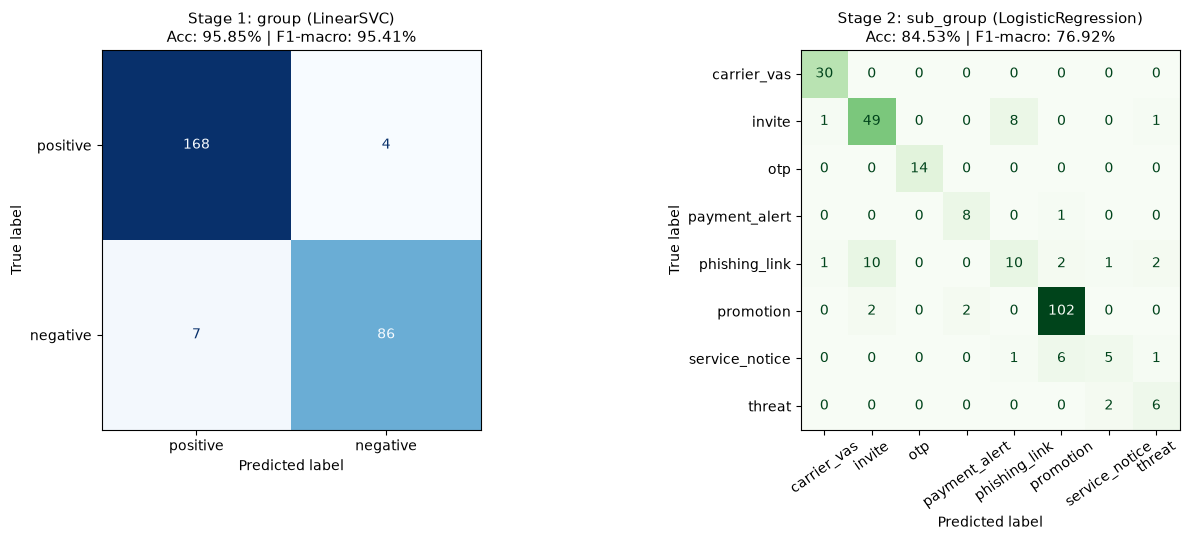

In [30]:
def train_hierarchical_models(X_train_vec, y_train) -> dict:
    """เทรนโมเดล 2 ชั้น: ชั้นที่ 1 แยก group (LinearSVC), ชั้นที่ 2 แยก sub_group (LogisticRegression)"""
    # ขั้นที่ 1: แยก positive / negative
    model_group = CalibratedClassifierCV(
        LinearSVC(C=1.0, class_weight="balanced", random_state=42), cv=3
    )
    model_group.fit(X_train_vec, y_train["group"])

    # ขั้นที่ 2: แยก sub_group เฉพาะทางของแต่ละ group
    pos_mask = (y_train["group"] == "positive").values
    neg_mask = (y_train["group"] == "negative").values

    model_sub_pos = LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced", random_state=42)
    model_sub_pos.fit(X_train_vec[pos_mask], y_train.loc[pos_mask, "sub_group"])

    model_sub_neg = LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced", random_state=42)
    model_sub_neg.fit(X_train_vec[neg_mask], y_train.loc[neg_mask, "sub_group"])

    return {"group": model_group, "sub_pos": model_sub_pos, "sub_neg": model_sub_neg}


def predict_hierarchical(X_vec, models: dict):
    """ทำนายแบบกลุ่ม (Batch) สำหรับประเมินผลบน Test Set"""
    pred_grp = models["group"].predict(X_vec)
    pred_sub = np.empty(len(pred_grp), dtype=object)

    is_pos = pred_grp == "positive"
    if is_pos.any():
        pred_sub[is_pos] = models["sub_pos"].predict(X_vec[is_pos])
    if (~is_pos).any():
        pred_sub[~is_pos] = models["sub_neg"].predict(X_vec[~is_pos])
    return pred_grp, pred_sub


def predict_sms(raw_text: str, vectorizer, models: dict) -> dict:
    """ฟังก์ชันพร้อมใช้สำหรับ FastAPI: รับข้อความดิบ 1 ข้อความ -> คืนผลทำนายแบบ JSON dict"""
    tagged = normalize_sms(raw_text)
    cleaned, _ = preprocess(tagged)
    tokens = tokenize(cleaned)
    X_vec = vectorizer.transform([" ".join(tokens)])

    # ทำนาย group พร้อมความมั่นใจ
    grp_probs = models["group"].predict_proba(X_vec)[0]
    grp_idx = int(np.argmax(grp_probs))
    group = str(models["group"].classes_[grp_idx])

    # เลือกโมเดลย่อยตาม group ที่ทายได้
    sub_model = models["sub_pos"] if group == "positive" else models["sub_neg"]
    sub_probs = sub_model.predict_proba(X_vec)[0]
    sub_idx = int(np.argmax(sub_probs))

    return {
        "group": group,
        "group_confidence": round(float(grp_probs[grp_idx]), 4),
        "sub_group": str(sub_model.classes_[sub_idx]),
        "sub_group_confidence": round(float(sub_probs[sub_idx]), 4),
    }


# เทรนโมเดลและแสดงผลบน Test Set
models = train_hierarchical_models(X_train_vec, y_train)
y_pred_group, y_pred_sub = predict_hierarchical(X_test_vec, models)
plot_hierarchical_results(y_test["group"], y_pred_group, y_test["sub_group"], y_pred_sub)


### 2. วัดผลและปรับจูนโมเดล (Evaluation & Tuning)
- **วัดผลซ้ำเพื่อเช็กความเสถียร:** ทดสอบโมเดลทั้ง 2 ชั้น (`group` และ `sub_group` แยก `positive` / `negative`) ด้วยการแบ่งข้อมูลหลายรอบ เพื่อดูว่าค่าความแม่นยำนิ่งจริงหรือไม่
- **วิเคราะห์จุดที่โมเดลยังทายพลาด:** ดูรายละเอียดคะแนนรายคลาส (Precision, Recall, F1) และเช็กข้อความที่ทายผิด โดยเฉพาะเคสที่มิจฉาชีพหลุดเป็น `positive` หรือคู่ `sub_group` ที่สับสนกัน
- **แนวทางปรับจูน:** ทดลองปรับค่าพารามิเตอร์ของโมเดลแต่ละตัวใน `models` (หรือปรับการตั้งค่า/เพิ่ม feature เสริม เช่น `has_obfuscation`) เพื่อให้ได้ผลลัพธ์ที่ดีที่สุดและใช้เวลาประมวลผลเหมาะสม

In [31]:
# ---------- ฟังก์ชันช่วยสำหรับข้อ 2 ----------
# ค่าตั้งเริ่มต้น = ค่าเดียวกับที่ใช้ในข้อ 1 (build_vectorizer + train_hierarchical_models)
BASE_CFG = {
    "ngram_range": (1, 2), "min_df": 2, "max_df": 0.9, "max_features": 5000,
    "char_ngram": None,                       # เช่น (2, 4) = เพิ่ม TF-IDF ระดับตัวอักษร (char_wb)
    "C_group": 1.0, "C_sub_pos": 2.0, "C_sub_neg": 2.0,
}


def build_vectorizer_cfg(cfg: dict):
    """สร้าง vectorizer ตาม cfg (ยังเรียก .transform() ได้เหมือนเดิมใน predict_sms)"""
    word = TfidfVectorizer(
        ngram_range=cfg["ngram_range"], sublinear_tf=True, min_df=cfg["min_df"],
        max_df=cfg["max_df"], max_features=cfg["max_features"], token_pattern=r"(?u)\S+",
    )
    if cfg["char_ngram"] is None:
        return word
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=cfg["char_ngram"], sublinear_tf=True, min_df=2, max_features=20000)
    return FeatureUnion([("word", word), ("char", char)])


def train_models_cfg(X_vec, y, cfg: dict) -> dict:
    """เหมือน train_hierarchical_models แต่ปรับค่า C ได้ (คืน dict โครงสร้างเดิม {"group", "sub_pos", "sub_neg"})"""
    model_group = CalibratedClassifierCV(LinearSVC(C=cfg["C_group"], class_weight="balanced", random_state=42), cv=3)
    model_group.fit(X_vec, y["group"])
    out = {"group": model_group}
    for key, grp in [("sub_pos", "positive"), ("sub_neg", "negative")]:
        mask = (y["group"] == grp).values
        m = LogisticRegression(max_iter=2000, C=cfg[f"C_{key}"], class_weight="balanced", random_state=42)
        m.fit(X_vec[mask], y.loc[mask, "sub_group"])
        out[key] = m
    return out


def cv_evaluate(tokens: pd.Series, y: pd.DataFrame, cfg: dict, n_splits=5, n_repeats=3,
                random_state=42, extra_feature: pd.Series | None = None) -> pd.DataFrame:
    """แบ่งข้อมูลหลายรอบ (Repeated Stratified K-Fold) แล้ววัดผลโมเดลทั้ง 2 ชั้นทุกรอบ
    - vectorizer ถูก fit ใหม่ทุกรอบ -> ไม่มี data leakage
    - extra_feature: feature เสริม 1 คอลัมน์ (เช่น has_obfuscation)"""
    texts = tokens.apply(" ".join).to_numpy()
    y = y.reset_index(drop=True)
    extra = None if extra_feature is None else extra_feature.to_numpy(dtype=float).reshape(-1, 1)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    rows = []
    for tr, te in rskf.split(texts, y["sub_group"]):
        t0 = time.perf_counter()
        vec = build_vectorizer_cfg(cfg)
        X_tr, X_te = vec.fit_transform(texts[tr]), vec.transform(texts[te])
        if extra is not None:
            X_tr = hstack([X_tr, csr_matrix(extra[tr])]).tocsr()
            X_te = hstack([X_te, csr_matrix(extra[te])]).tocsr()
        y_tr, y_te = y.iloc[tr].reset_index(drop=True), y.iloc[te].reset_index(drop=True)
        ms = train_models_cfg(X_tr, y_tr, cfg)
        fit_sec = time.perf_counter() - t0

        pred_grp, pred_sub = predict_hierarchical(X_te, ms)
        pos = (y_te["group"] == "positive").values
        rows.append({
            # ชั้นที่ 1: group
            "group_f1":    f1_score(y_te["group"], pred_grp, average="macro"),
            "scam_recall": recall_score(y_te["group"], pred_grp, pos_label="negative"),   # มิจฉาชีพที่จับได้ / ทั้งหมด
            # ชั้นที่ 2: sub_group แยก positive / negative (สมมติว่าชั้นที่ 1 ทายถูก)
            "sub_pos_f1":  f1_score(y_te.loc[pos, "sub_group"], ms["sub_pos"].predict(X_te[pos]), average="macro"),
            "sub_neg_f1":  f1_score(y_te.loc[~pos, "sub_group"], ms["sub_neg"].predict(X_te[~pos]), average="macro"),
            # ทั้ง 2 ชั้นรวมกัน (end-to-end)
            "sub_f1":      f1_score(y_te["sub_group"], pred_sub, average="macro"),
            "fit_sec":     fit_sec,
        })
    return pd.DataFrame(rows)


def run_experiments(experiments: dict, tokens, y, n_repeats=2, **kw) -> pd.DataFrame:
    """รัน cv_evaluate หลายการตั้งค่า -> ตารางค่าเฉลี่ย (1 แถว = 1 การตั้งค่า)"""
    return pd.DataFrame({name: cv_evaluate(tokens, y, cfg, n_repeats=n_repeats, **kw).mean()
                         for name, cfg in experiments.items()}).T

#### วัดผลซ้ำเพื่อเช็กความเสถียร
แบ่งข้อมูล 5-Fold × 3 รอบ = 15 ครั้ง (stratify ตาม `sub_group`) แล้ววัดโมเดลทั้ง 2 ชั้น: `group` และ `sub_group` แยก `positive` (`sub_pos_f1`) / `negative` (`sub_neg_f1`)

,mean,std,min,max
group_f1,0.9532,0.0137,0.9233,0.9792
scam_recall,0.9221,0.0329,0.8587,0.9783
sub_pos_f1,0.8879,0.0287,0.8388,0.9314
sub_neg_f1,0.7052,0.0404,0.6016,0.7449
sub_f1,0.7804,0.0293,0.7059,0.8186
fit_sec,0.2470,0.0289,0.2150,0.2974


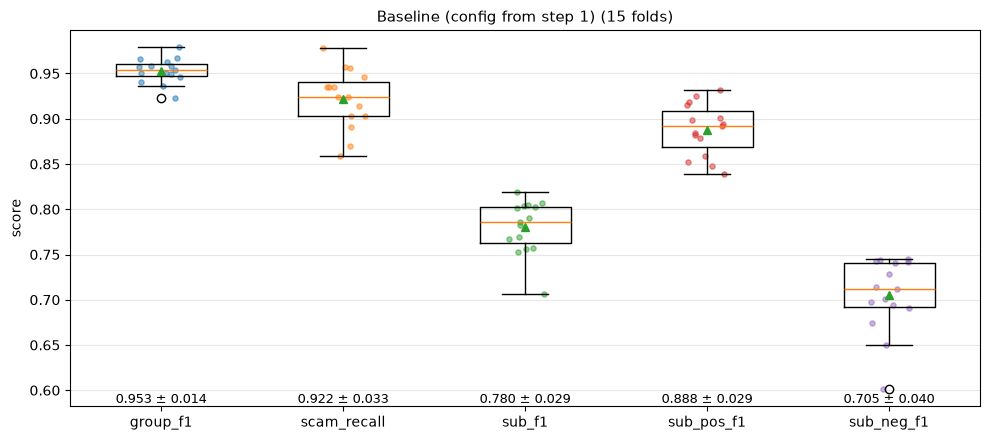

In [32]:
cv_base = cv_evaluate(df["tokens"], df[["group", "sub_group"]], BASE_CFG, n_splits=5, n_repeats=3)
display(cv_base.agg(["mean", "std", "min", "max"]).T.round(4))
plot_cv_stability(cv_base, title="Baseline (config from step 1)")

#### วิเคราะห์จุดที่โมเดลยังทายพลาด
ใช้โมเดลจากข้อ 1 กับ Test Set: ดูคะแนนรายคลาส (Precision, Recall, F1), มิจฉาชีพที่หลุดเป็น `positive` และคู่ `sub_group` ที่สับสนกัน

In [33]:
print("=== group ===")
print(classification_report(y_test["group"], y_pred_group, digits=4))
print("=== sub_group ===")
print(classification_report(y_test["sub_group"], y_pred_sub, digits=4, zero_division=0))

# id, sentence_raw, group, sub_group = คอลัมน์เดิมจาก data_set.csv (คำตอบจริง)
# ทาย_group, ทาย_sub_group           = สิ่งที่โมเดลทาย (ไม่มีใน data)
errors = df.loc[X_test.index, ["id", "sentence_raw", "group", "sub_group"]].assign(
    ทาย_group=y_pred_group, ทาย_sub_group=y_pred_sub
).set_index("id")

missed_scam = errors[(errors["group"] == "negative") & (errors["ทาย_group"] == "positive")]
sub_wrong   = errors[(errors["group"] == errors["ทาย_group"]) & (errors["sub_group"] != errors["ทาย_sub_group"])]

with pd.option_context("display.max_colwidth", 120):
    # โมเดลชั้นที่ 1 ทาย group ผิดเป็น positive -> ชั้นที่ 2 จึงเลือก sub_group ได้แค่หมวดของ positive
    print(f"มิจฉาชีพที่หลุดเป็น positive: {len(missed_scam)} ข้อความ")
    display(missed_scam)
    print(f"group ถูกแต่ sub_group ผิด ({len(sub_wrong)} ข้อความ) — คู่ที่สับสนกัน:")
    display(sub_wrong.groupby(["sub_group", "ทาย_sub_group"]).size().rename("จำนวน").sort_values(ascending=False).to_frame())
    display(sub_wrong)

=== group ===
              precision    recall  f1-score   support

    negative     0.9556    0.9247    0.9399        93
    positive     0.9600    0.9767    0.9683       172

    accuracy                         0.9585       265
   macro avg     0.9578    0.9507    0.9541       265
weighted avg     0.9584    0.9585    0.9583       265

=== sub_group ===
                precision    recall  f1-score   support

   carrier_vas     0.9375    1.0000    0.9677        30
        invite     0.8033    0.8305    0.8167        59
           otp     1.0000    1.0000    1.0000        14
 payment_alert     0.8000    0.8889    0.8421         9
 phishing_link     0.5263    0.3846    0.4444        26
     promotion     0.9189    0.9623    0.9401       106
service_notice     0.6250    0.3846    0.4762        13
        threat     0.6000    0.7500    0.6667         8

      accuracy                         0.8453       265
     macro avg     0.7764    0.7751    0.7692       265
  weighted avg     0.83

,sentence_raw,group,sub_group,ทาย_group,ทาย_sub_group
id,,,,,
742,OVERB พิเศษทั้งวัน รับทันทีลด50% คลิกเข้าเกมเลย,negative,phishing_link,positive,promotion
1302,ประกาศ: ซิมการ์ดหมายเลขนี้จะถูกระงับสัญญาณภายใน 2 ชม. เนื่องจากข้อมูลไม่สมบูรณ์ อัปเดตที่ lin.ee/sim-kyc,negative,threat,positive,service_notice
107,โหลดฟรี! เพลงรอสาย รักแท้ (Cover Version)-New Country แถมฟรีค่าบริการเดือนแรก bit.ly/45HHwtv,negative,phishing_link,positive,carrier_vas
121,คะแนนสะสม AIS Points ของคุณกำลังจะหมดอายุ อย่าลืมแลกของรางวัล,negative,phishing_link,positive,service_notice
670,ดูดวงพร้อมแนะนำเบอร์มงคลเปลี่ยนชีวิตให้ปัง กดเลย bit.ly/3fxQwcL,negative,phishing_link,positive,promotion
753,เพิ่มเงินค่าโทร 500บ.ฟรี! ลุ้นรับกด *298*550# สมัครลุ้นรหัสรวย(9บ/วัน),negative,invite,positive,carrier_vas
452,คุณถูกลบออกจากบัญชี Microsoft ไม่ใช่คุณใช่หรือไม่ <URL>,negative,threat,positive,service_notice


group ถูกแต่ sub_group ผิด (30 ข้อความ) — คู่ที่สับสนกัน:


,,จำนวน
sub_group,ทาย_sub_group,
phishing_link,invite,10
invite,phishing_link,8
service_notice,promotion,6
phishing_link,threat,2
promotion,payment_alert,2
payment_alert,promotion,1
invite,threat,1


,sentence_raw,group,sub_group,ทาย_group,ทาย_sub_group
id,,,,,
1323,กู้เงินฉุกเฉินผ่านแอป ไม่หักค่าธรรมเนียมล่วงหน้า โอนไว 100% สนใจคลิก lin.ee/quickloan24,negative,invite,negative,phishing_link
636,เจ้าหน้าที่ได้คำนวณค่าFTไฟฟ้าผิดพลาด จึงทำให้ค่าไฟของท่านสูงผิดปกติ กรุณาติดต่อเจ้าหน้าที่ line.me/ti/p/WfPziPXBa_,negative,phishing_link,negative,threat
565,จากประสบการณ์การใช้งานมือถือเครือข่ายทรู ท่านพอใจและจะแนะนำให้เพื่อน/ครอบครัวมาใช้มือถือเครือข่ายทรูมากน้อยเพียงใด โ...,positive,service_notice,positive,promotion
903,SHARP มอบเตาอบให้คุณฟรีติดต่อฝ่ายบริการLINE： https://bit.ly/3ydKMyu,negative,phishing_link,negative,invite
59,"คุณได้รับสินเชื่อ GSB ออมสิน 50,000 ติดต่อ: line.me/ti/p/A-L83iDlyO",negative,phishing_link,negative,invite
691,(SCB)หาเงินก้อนโต กู้ได้ทุกอาชีพ อนุมัติวันเดียว คลิ๊ก:bit.do/TCBTH,negative,phishing_link,negative,invite
199,สวัสดีค่ะ ยินดีด้วยคุณเป็นผู้โชคดีจากTikTok ตอนนี้คุณได้รับเชิญทำงานหารายได้เสริมบน TikTokเพียงแค่กดไลค์กดติดตาม ทำร...,negative,invite,negative,phishing_link
986,คุณได้เข้าร่วมโครงการ “เอไอเอส พอยท์” สะสมคะแนนจากทุกการใช้งาน 25 บ.=1 คะแนน ดูสิทธิพิเศษได้ที่แอป myAIS <URL>,positive,service_notice,positive,promotion
597,แพ็กเกจ ฟรี เน็ตเต็มสปีด 1GB 1 วัน ใช้งานได้ถึง 08/10/2026 00:36:14 เช็กเงิน เช็กเน็ตคงเหลือ หรือซื้อแพ็กเกจเสริมเฉพ...,positive,payment_alert,positive,promotion


#### แนวทางปรับจูน
ปรับบน Train Set ด้วยการแบ่งข้อมูลหลายรอบ (5-Fold × 2 รอบ): ตั้งค่า vectorizer → ค่า `C` ของแต่ละโมเดลใน `models` → ลองเพิ่ม feature `has_obfuscation` แล้วเลือกค่าที่ดีที่สุดโดยดูเวลาประมวลผล (`fit_sec`) ประกอบ

In [34]:
# ปรับการตั้งค่า vectorizer (ใช้ C เท่าเดิม) -> เลือกด้วย sub_f1
vec_experiments = {
    "base: word(1,2)":       {},
    "word(1,1)":             {"ngram_range": (1, 1)},
    "word(1,3)":             {"ngram_range": (1, 3)},
    "word(1,2) min_df=1":    {"min_df": 1},
    "word(1,2) + char(2,4)": {"char_ngram": (2, 4)},
    "word(1,2) + char(2,5)": {"char_ngram": (2, 5)},
}
vec_experiments = {k: {**BASE_CFG, **v} for k, v in vec_experiments.items()}
tune_vec = run_experiments(vec_experiments, X_train, y_train)
display(tune_vec.round(4).sort_values("sub_f1", ascending=False))

BEST_CFG = dict(vec_experiments[tune_vec["sub_f1"].idxmax()])
print("vectorizer ที่เลือก:", tune_vec["sub_f1"].idxmax())

,group_f1,scam_recall,sub_pos_f1,sub_neg_f1,sub_f1,fit_sec
"word(1,2) + char(2,4)",0.9508,0.9216,0.8747,0.7301,0.7732,0.5397
"word(1,2) min_df=1",0.9415,0.8997,0.8666,0.7200,0.7717,0.1932
"word(1,2) + char(2,5)",0.9513,0.9229,0.8716,0.7228,0.7688,0.5871
"base: word(1,2)",0.9410,0.8998,0.8630,0.7176,0.7676,0.1809
"word(1,3)",0.9421,0.9039,0.8621,0.7178,0.7666,0.2236
"word(1,1)",0.9433,0.9080,0.8595,0.7062,0.7573,0.0830


vectorizer ที่เลือก: word(1,2) + char(2,4)


In [35]:
# ปรับค่า C ของแต่ละโมเดลใน models
# group เลือกด้วย group_f1, sub_pos / sub_neg เลือกด้วย F1 ของโมเดลย่อยตัวนั้น (เทรนแยกกันจึงจูนพร้อมกันได้)
C_GRID = [0.1, 0.3, 1.0, 3.0, 10.0]
tune_C_group = run_experiments({c: {**BEST_CFG, "C_group": c} for c in C_GRID}, X_train, y_train)
tune_C_sub   = run_experiments({c: {**BEST_CFG, "C_sub_pos": c, "C_sub_neg": c} for c in C_GRID}, X_train, y_train)
display(tune_C_group[["group_f1", "scam_recall"]].rename_axis("C_group").round(4))
display(tune_C_sub[["sub_pos_f1", "sub_neg_f1"]].rename_axis("C_sub").round(4))

BEST_CFG["C_group"]   = float(tune_C_group["group_f1"].idxmax())
BEST_CFG["C_sub_pos"] = float(tune_C_sub["sub_pos_f1"].idxmax())
BEST_CFG["C_sub_neg"] = float(tune_C_sub["sub_neg_f1"].idxmax())
print("BEST_CFG:", BEST_CFG)

,group_f1,scam_recall
C_group,,
0.1,0.9437,0.9054
0.3,0.9480,0.9148
1.0,0.9508,0.9216
3.0,0.9508,0.9229
10.0,0.9508,0.9215


,sub_pos_f1,sub_neg_f1
C_sub,,
0.1,0.8671,0.7340
0.3,0.8694,0.7397
1.0,0.8716,0.7290
3.0,0.8757,0.7252
10.0,0.8801,0.7250


BEST_CFG: {'ngram_range': (1, 2), 'min_df': 2, 'max_df': 0.9, 'max_features': 5000, 'char_ngram': (2, 4), 'C_group': 3.0, 'C_sub_pos': 10.0, 'C_sub_neg': 0.3}


In [36]:
# ลองเพิ่ม feature has_obfuscation (ข้อความที่สะกดเลี่ยง เช่น ถoน)
display(df.groupby("group")["has_obfuscation"].sum().rename("has_obfuscation=1").to_frame())
obf_results = pd.DataFrame({
    "BEST_CFG":                   cv_evaluate(X_train, y_train, BEST_CFG, n_repeats=2).mean(),
    "BEST_CFG + has_obfuscation": cv_evaluate(X_train, y_train, BEST_CFG, n_repeats=2,
                                              extra_feature=df.loc[X_train.index, "has_obfuscation"]).mean(),
}).T
display(obf_results.round(4))

,has_obfuscation=1
group,
negative,23
positive,1


,group_f1,scam_recall,sub_pos_f1,sub_neg_f1,sub_f1,fit_sec
BEST_CFG,0.9508,0.9229,0.8801,0.7397,0.7794,0.5099
BEST_CFG + has_obfuscation,0.9492,0.9201,0.8801,0.7437,0.7802,0.5034


In [37]:
# เทียบผลก่อน/หลังปรับจูน (แบ่งข้อมูล 5-Fold × 3 รอบเหมือนตอนเช็กความเสถียร)
cv_tuned = cv_evaluate(df["tokens"], df[["group", "sub_group"]], BEST_CFG, n_splits=5, n_repeats=3)
display(pd.DataFrame({"baseline": cv_base.mean(), "tuned": cv_tuned.mean()})
        .assign(diff=lambda d: d.tuned - d.baseline).round(4))

# เทรนโมเดลที่ปรับจูนแล้วบน Train Set -> ใช้ต่อในข้อ 3
vectorizer = build_vectorizer_cfg(BEST_CFG)
X_train_vec = vectorizer.fit_transform(X_train.apply(" ".join))
X_test_vec  = vectorizer.transform(X_test.apply(" ".join))
models = train_models_cfg(X_train_vec, y_train, BEST_CFG)

,baseline,tuned,diff
group_f1,0.9532,0.9572,0.0040
scam_recall,0.9221,0.9286,0.0065
sub_pos_f1,0.8879,0.8890,0.0011
sub_neg_f1,0.7052,0.7390,0.0338
sub_f1,0.7804,0.7975,0.0171
fit_sec,0.2470,0.6247,0.3776


### 3. ทดสอบใช้งานจริง & บันทึกโมเดลสำหรับ API (Inference & Export)
- **ทดสอบกับข้อความ SMS ดิบ:** ลองส่งข้อความใหม่ๆ ผ่านฟังก์ชัน `predict_sms(raw_text, vectorizer, models)` เพื่อเช็กความถูกต้องของ `group`, `sub_group` และค่าความมั่นใจที่ได้
- **แนวทางส่งต่อให้ฝั่ง API:** บันทึกตัว `vectorizer` และ `models` (`{"group", "sub_pos", "sub_neg"}`) ที่ปรับจูนเสร็จแล้วเก็บไว้เป็นไฟล์ พร้อมแนบฟังก์ชันเตรียมข้อความ (`normalize_sms`, `preprocess`, `tokenize`, `predict_sms`) เพื่อนำไปโหลดใช้งานในฝั่ง Backend API ต่อไป

In [ ]:
# 3.1 ทดสอบกับข้อความ SMS ดิบ 
test_messages = [
    "รหัส OTP ของคุณคือ 482913 (Ref. AB12CD) ใช้ได้ภายใน 5 นาที ห้ามบอกรหัสนี้กับผู้อื่น",
    "ธนาคารแจ้งเงินเข้าบัญชี x1234 จำนวน 1,500.00 บาท วันที่ 15/11/2569 เวลา 10:32 น.",
    "สะสมครบ 500 บาท รับส่วนลดทันที 50 บาท ที่ร้านค้าที่ร่วมรายการ ตั้งแต่วันนี้ถึง 30 พ.ย.",
    "ดูดวงรายวัน กด *123*45# ค่าบริการ 6 บาท/วัน ยกเลิกโทร 1175",
    "พัสดุของท่านถึงจุดรับสินค้าแล้ว กรุณามารับภายใน 3 วัน",
    "รับเครดิตฟรี 300 สมัครวันนี้ เว็บตรง ฝากถอนไม่มีขั้นต่ำ ไลน์ @bet789",
    "บัญชีของท่านถูกระงับชั่วคราว กรุณายืนยันตัวตนที่ http://kbank-verify.xyz/login",
    "พัสดุของคุณถูกอายัดที่ศุลกากร ติดต่อภายใน 24 ชม. มิฉะนั้นจะถูกดำเนินคดี",
]

test_result = pd.DataFrame(
    [{"ข้อความ": m, **predict_sms(m, vectorizer, models)} for m in test_messages]
)
with pd.option_context("display.max_colwidth", 60, "display.width", 220):
    display(test_result)


# 3.2 บันทึก vectorizer และ models 
MODEL_PATH = "sms_model.joblib"
joblib.dump({"vectorizer": vectorizer, "models": models}, MODEL_PATH, compress=3)


# 3.3 แนบฟังก์ชันเตรียมข้อความ (สร้างเป็นไฟล์ sms_pipeline.py) 
REGEX_NAMES = ["URL_RE", "LINE_RE", "USSD_RE", "DATE_RE", "TIME_RE", "OTP_RE", "OTP_TH_RE",
               "REF_RE", "REF_TH_RE", "PHONE_RE", "AMOUNT_RE",
               "_UNIT", "_CHUNK", "_ZERO_WIDTH", "_PAREN"]
EXPORT_FUNCS = [_word_cost, _cost, _fix_chunk, normalize_sms, preprocess, tokenize, predict_sms]

module_header = f'''"""โมดูลเตรียมข้อความ SMS สำหรับ Backend API (สร้างอัตโนมัติจาก main.ipynb)"""
import re, math, unicodedata, itertools
from functools import lru_cache
import numpy as np
from pythainlp.tokenize import word_tokenize
from pythainlp.util import normalize as th_normalize
from pythainlp.corpus import thai_words
from pythainlp.corpus.tnc import word_freqs

LOOKALIKES = {LOOKALIKES!r}
_FREQ = dict(word_freqs())
_LOG_TOTAL = math.log(sum(_FREQ.values()))
_DICT = set(thai_words())
'''
regex_defs = "\n".join(f"{n} = re.compile({globals()[n].pattern!r}, {globals()[n].flags})" for n in REGEX_NAMES)
func_defs  = "\n\n".join(inspect.getsource(f) for f in EXPORT_FUNCS)

with open("sms_pipeline.py", "w", encoding="utf-8") as f:
    f.write(module_header + "\n" + regex_defs + "\n\n\n" + func_defs + "\n")

print(f"บันทึกแล้ว: {MODEL_PATH} (vectorizer + models) และ sms_pipeline.py (ฟังก์ชันเตรียมข้อความ)")


,ข้อความ,group,group_confidence,sub_group,sub_group_confidence
0,รหัส OTP ของคุณคือ 482913 (Ref. AB12CD) ใช้ได้ภายใน 5 นา...,positive,0.9976,otp,0.9962
1,"ธนาคารแจ้งเงินเข้าบัญชี x1234 จำนวน 1,500.00 บาท วันที่ ...",positive,0.8799,payment_alert,0.7648
2,สะสมครบ 500 บาท รับส่วนลดทันที 50 บาท ที่ร้านค้าที่ร่วมร...,positive,0.9571,promotion,0.9392
3,ดูดวงรายวัน กด *123*45# ค่าบริการ 6 บาท/วัน ยกเลิกโทร 1175,positive,0.9982,carrier_vas,0.9462
4,พัสดุของท่านถึงจุดรับสินค้าแล้ว กรุณามารับภายใน 3 วัน,negative,0.9650,threat,0.5105
5,รับเครดิตฟรี 300 สมัครวันนี้ เว็บตรง ฝากถอนไม่มีขั้นต่ำ ...,negative,0.9991,invite,0.7530
6,บัญชีของท่านถูกระงับชั่วคราว กรุณายืนยันตัวตนที่ http://...,negative,0.9643,threat,0.5208
7,พัสดุของคุณถูกอายัดที่ศุลกากร ติดต่อภายใน 24 ชม. มิฉะนั้...,negative,0.9911,threat,0.6162


บันทึกแล้ว: sms_model.joblib (vectorizer + models) และ sms_pipeline.py (ฟังก์ชันเตรียมข้อความ)
